In [1]:
import pandas as pd
import jellyfish
import math
import matplotlib.pyplot as plt


In [2]:
data = pd.read_csv('./data/pokeguess/cumulative_database.csv', index_col='Number')

In [3]:
def save_db():
    data.to_csv('./data/pokeguess/cumulative_database.csv')

In [4]:
col_type = {'Type 1': 'cat',
            'Type 2': 'cat',
            'HP': 'int',
            'Attack': 'int',
            'Defense': 'int',
            'Sp.Attack': 'int',
            'Sp.Defense': 'int',
            'Speed': 'int',
            'E. Stage': 'int',
            'F. Evolved': 'bool',
            'Color': 'tuple int',
            'Habitats': 'tuple cat',
            'Generation': 'int',
            'Height': 'float',
            'Weight': 'float'}

In [5]:
import pandas as pd
import numpy as np
import random

np.random.seed(42)
random.seed(42)

n = 100

# Gaussiane per colonne numeriche
gauss_1 = np.random.normal(loc=50, scale=10, size=(n // 2, 6))  # HP, Attack...
gauss_2 = np.random.normal(loc=100, scale=15, size=(n // 2, 6))
numeric_stats = np.vstack([gauss_1, gauss_2])
numeric_stats = np.clip(numeric_stats, 0, None).astype(int)

# Speed (altra distribuzione simile)
speed = np.clip(np.random.normal(60, 20, size=n), 0, None).astype(int)

# Categoriche non uniformi
type_options = ['Fire', 'Water', 'Grass', 'Electric', 'Normal', 'Dragon']
type1 = np.random.choice(type_options, size=n, p=[0.3, 0.25, 0.15, 0.15, 0.1, 0.05])
type2 = np.random.choice(type_options + [None], size=n, p=[0.2, 0.2, 0.15, 0.15, 0.1, 0.05, 0.15])

# Color tuples (RGB)
colors = [tuple(np.random.randint(0, 256, size=3)) for _ in range(n)]

# Habitat tuples
habitat_pool = ['Forest', 'Ocean', 'Cave', 'Urban', 'Desert']
habitats = [tuple(np.random.choice(habitat_pool, size=2, replace=False)) for _ in range(n)]

# Altri dati
e_stage = np.random.randint(1, 4, size=n)
f_evolved = np.random.choice([True, False], size=n, p=[0.6, 0.4])
generation = np.random.randint(1, 9, size=n)
height = np.abs(np.random.normal(1.5, 0.5, size=n)).round(2)
weight = np.abs(np.random.normal(40, 20, size=n)).round(2)

# Costruzione DataFrame
df = pd.DataFrame({
    'Type 1': type1,
    'Type 2': type2,
    'HP': numeric_stats[:, 0],
    'Attack': numeric_stats[:, 1],
    'Defense': numeric_stats[:, 2],
    'Sp.Attack': numeric_stats[:, 3],
    'Sp.Defense': numeric_stats[:, 4],
    'Speed': speed,
    'E. Stage': e_stage,
    'F. Evolved': f_evolved,
    'Color': colors,
    'Habitats': habitats,
    'Generation': generation,
    'Height': height,
    'Weight': weight
})

df.sample(2)


,Type 1,Type 2,HP,Attack,Defense,Sp.Attack,Sp.Defense,Speed,E. Stage,F. Evolved,Color,Habitats,Generation,Height,Weight
75,Electric,Fire,99,114,85,107,92,44,1,True,"(202, 26, 194)","(Urban, Ocean)",2,2.16,66.25
82,Fire,None,101,87,122,108,84,49,1,True,"(0, 57, 123)","(Urban, Forest)",3,1.21,31.36


In [47]:
def search_distance(small, long):
    
    # if len(small) > len(long):
    #    small, long = long, small
    
    d_1 = jellyfish.damerau_levenshtein_distance(small,long)/len(small) + (1-jellyfish.jaro_winkler_similarity(small,long))
    
    d_2 = jellyfish.damerau_levenshtein_distance(small,long.replace('-f','').replace('-m',''))/len(small) + (1-jellyfish.jaro_winkler_similarity(small,long.replace('-f','').replace('-m','')))

    d_3 = jellyfish.damerau_levenshtein_distance(small,long.replace('-gigamax','').replace('-m',''))/len(small) + (1-jellyfish.jaro_winkler_similarity(small,long.replace('-gigamax','').replace('-m','')))
    
    ret = min(d_1, d_2*1.1, d_3*1.2)
    
    
    if long.startswith(small):
        ret = ret/2
    elif small in long:
        ret =  ret/2

    return ret        
                       
def compute_expected_gain(data, cols):
    
    gains = []
    
    for i, val in data.iterrows():
        
        gain = 0
        
        for c in cols:
            if col_type[c] == 'int' or col_type[c] == 'float':
                upper = len([x for x in data[c] if x > val[c]])
                lower = len([x for x in data[c] if x < val[c]])
                
                min_gain = max(upper, lower) / len(data[c])
                gain += min_gain
                
            elif col_type[c] == 'cat' or col_type[c] == 'bool':
                
                equal = len([x for x in data[c] if x == val[c]])
                diff = len([x for x in data[c] if x != val[c]])
                
                min_gain = max(equal, diff) / len(data[c])
                gain += min_gain

        gains.append(gain)
    
    return gains
        
def filter(data, index, mask, cols):
    
    new_d = data
    pivot = new_d.loc[index, :]
    
    for c in cols:
        if col_type[c] == 'int' or col_type[c] == 'float':
            if mask[c] == 0:   
                new_d = new_d.loc[pivot[c] > new_d.loc[:,c]]
            elif mask[c] == 1:
                new_d = new_d.loc[pivot[c] == new_d.loc[:,c]]
            else:
                new_d = new_d.loc[pivot[c] < new_d.loc[:,c]]
                
        
        elif col_type[c] == 'cat' or col_type[c] == 'bool':
            
            continue
        
    return new_d

In [58]:
mask = {x:2 for x in df.columns}

In [59]:
filter(df, 1, mask, list(df.columns))

,Type 1,Type 2,HP,Attack,Defense,Sp.Attack,Sp.Defense,Speed,E. Stage,F. Evolved,Color,Habitats,Generation,Height,Weight
55,Grass,None,99,86,101,89,114,61,3,True,"(191, 16, 11)","(Urban, Cave)",5,1.53,46.77
58,Fire,Grass,89,96,104,122,112,63,2,True,"(217, 119, 250)","(Ocean, Cave)",8,1.39,73.62
60,Electric,Water,107,122,98,106,110,48,2,True,"(191, 174, 28)","(Cave, Ocean)",8,1.62,63.33
70,Grass,Water,130,126,96,114,109,84,3,False,"(140, 232, 38)","(Urban, Cave)",6,1.64,72.62
78,Electric,None,92,91,95,65,77,78,3,False,"(20, 46, 207)","(Forest, Urban)",3,1.64,58.96
90,Normal,Water,112,83,107,121,62,52,3,True,"(52, 7, 78)","(Ocean, Urban)",5,1.78,77.24


In [22]:
a = compute_expected_gain(df, list(df.columns))

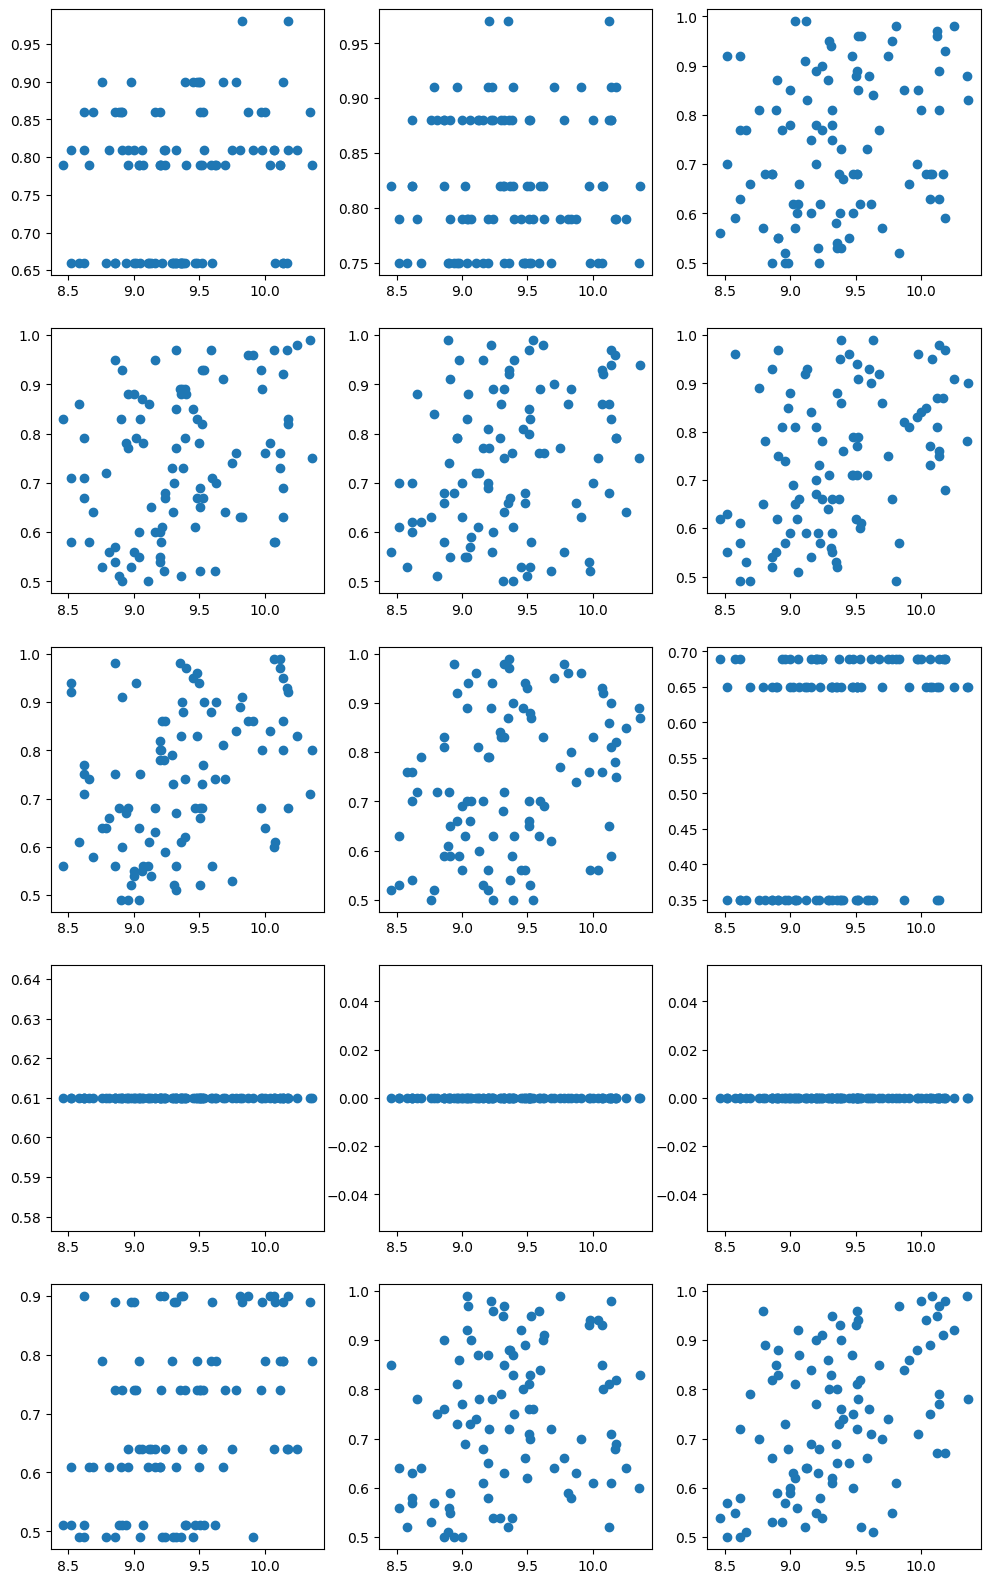

In [31]:
col = 3
row = math.ceil(len(df.columns)/col)

fig, axs = plt.subplots(row, col, figsize=(col*4,row*4))
axs = axs.flatten()

gain = compute_expected_gain(df, list(df.columns))
for i, c in enumerate(df.columns):
    
    a, b = zip(*sorted(zip(gain, compute_expected_gain(df, [c]))))

    # Se vuoi convertirle di nuovo in liste:
    a = list(a)
    b = list(b)

    axs[i].scatter(a, b)

In [ ]:
fig, axs = plt.subplots(1, 1, figsize=(col*4,row*4))

gain = compute_expected_gain(df, list(df.columns))
for i in range(100):
    s = df.sample(1)
    
    
    
for i, c in enumerate(df.columns):
    
    a, b = zip(*sorted(zip(gain, compute_expected_gain(df, [c]))))

    # Se vuoi convertirle di nuovo in liste:
    a = list(a)
    b = list(b)

    axs[i].scatter(a, b)

In [ ]:
s = df.sample(1)

KeyError: 0